Loading datasets...
Hardening Architectures...
Baseline RF Accuracy: 95.71%
Baseline LR Accuracy: 91.15%
Running Adversarial Stress Test across architectures...
Epsilon 0.00 | RF Acc: 95.7% | LR Acc: 91.1%
Epsilon 0.05 | RF Acc: 74.0% | LR Acc: 90.5%
Epsilon 0.10 | RF Acc: 67.5% | LR Acc: 87.6%
Epsilon 0.15 | RF Acc: 62.6% | LR Acc: 80.5%
Epsilon 0.20 | RF Acc: 59.5% | LR Acc: 68.3%
Epsilon 0.25 | RF Acc: 55.6% | LR Acc: 58.6%
Epsilon 0.30 | RF Acc: 52.5% | LR Acc: 50.5%
Epsilon 0.40 | RF Acc: 47.2% | LR Acc: 35.4%
Epsilon 0.50 | RF Acc: 40.4% | LR Acc: 25.0%


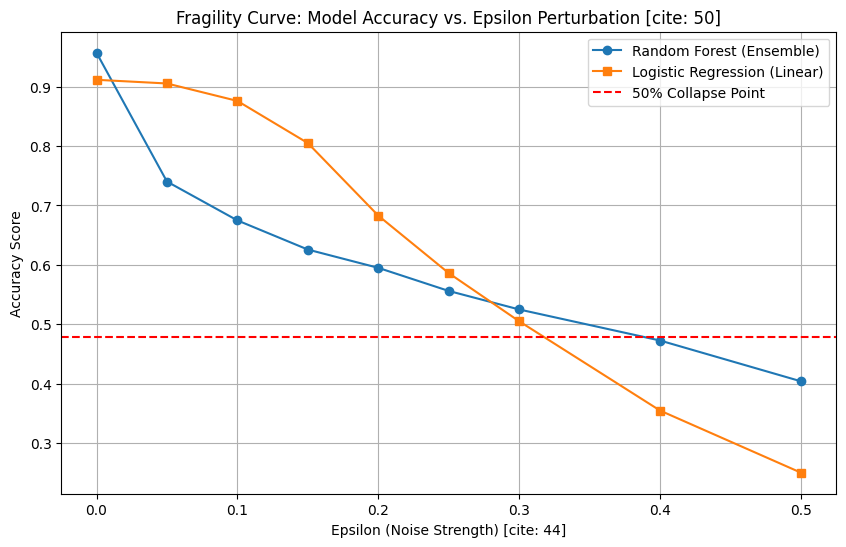

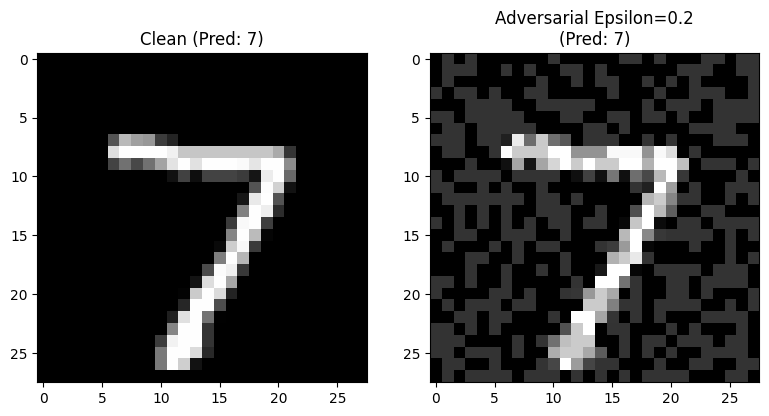

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer

# 1. DATA PREPARATION: Load Kaggle MNIST files
print("Loading datasets...")
train_df = pd.read_csv('mnist_train.csv')
test_df = pd.read_csv('mnist_test.csv')

# MNIST images are 28x28 = 784 pixels [cite: 1627]
# Scale pixel values to the [0, 1] range for normalization [cite: 1627]
X_train = train_df.iloc[:, 1:].values / 255.0
y_train = train_df.iloc[:, 0].values

X_test = test_df.iloc[:, 1:].values / 255.0
y_test = test_df.iloc[:, 0].values

# Handle NaN values using SimpleImputer, replacing them with 0
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# 2. MULTI-ARCHITECTURE HARDENING
print("Hardening Architectures...")

# Model A: Non-linear Tree-based (Random Forest)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Model B: Linear Classifier (Logistic Regression)
# Included to compare how hyperplane separation handles noise vs ensembles
lr_model = LogisticRegression(max_iter=100, solver='liblinear')
lr_model.fit(X_train, y_train)

rf_baseline = accuracy_score(y_test, rf_model.predict(X_test))
lr_baseline = accuracy_score(y_test, lr_model.predict(X_test))

print(f"Baseline RF Accuracy: {rf_baseline * 100:.2f}%")
print(f"Baseline LR Accuracy: {lr_baseline * 100:.2f}%")

# 3. PERTURBATION ENGINE [cite: 48]
def inject_noise(X, epsilon):
    """
    Systematically corrupts inputs by injecting random noise[cite: 48].
    ε (epsilon) determines the noise threshold[cite: 44, 48].
    """
    noise = np.random.normal(0, 1, X.shape)
    # Targeted nudge pushing inputs across decision boundaries [cite: 954]
    X_noisy = X + epsilon * np.sign(noise)
    return np.clip(X_noisy, 0, 1) # Ensure pixel values remain in valid range

# 4. COLLAPSE IDENTIFICATION: Generate Fragility Curves [cite: 50]
epsilons = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
rf_accuracies = []
lr_accuracies = []

print("Running Adversarial Stress Test across architectures...")
for eps in epsilons:
    X_test_adv = inject_noise(X_test, eps)

    # Evaluate Random Forest
    rf_acc = accuracy_score(y_test, rf_model.predict(X_test_adv))
    rf_accuracies.append(rf_acc)

    # Evaluate Logistic Regression
    lr_acc = accuracy_score(y_test, lr_model.predict(X_test_adv))
    lr_accuracies.append(lr_acc)

    print(f"Epsilon {eps:.2f} | RF Acc: {rf_acc*100:.1f}% | LR Acc: {lr_acc*100:.1f}%")

# 5. VISUALIZATION: Accuracy Decay Curves [cite: 50]
plt.figure(figsize=(10, 6))
plt.plot(epsilons, rf_accuracies, marker='o', label='Random Forest (Ensemble)')
plt.plot(epsilons, lr_accuracies, marker='s', label='Logistic Regression (Linear)')
plt.axhline(y=rf_baseline / 2, color='red', linestyle='--', label='50% Collapse Point')
plt.title("Fragility Curve: Model Accuracy vs. Epsilon Perturbation [cite: 50]")
plt.xlabel("Epsilon (Noise Strength) [cite: 44]")
plt.ylabel("Accuracy Score")
plt.grid(True)
plt.legend()
plt.show()

# 6. VISUAL AUDIT: Adversarial Twins [cite: 50]
# Demonstrates that shifted inputs look identical to humans but fool the model [cite: 1389, 2067]
sample_idx = 0
eps_audit = 0.2
clean_img = X_test[sample_idx].reshape(28, 28)
adv_img = inject_noise(X_test[sample_idx].reshape(1, -1), eps_audit).reshape(28, 28)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(clean_img, cmap='gray')
axes[0].set_title(f"Clean (Pred: {rf_model.predict(X_test[sample_idx].reshape(1,-1))[0]})")
axes[1].imshow(adv_img, cmap='gray')
axes[1].set_title(f"Adversarial Epsilon={eps_audit}\n(Pred: {rf_model.predict(adv_img.reshape(1,-1))[0]})")
plt.tight_layout()
plt.show()